### Importing Libraries

In [1]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [3]:
df=pd.read_csv("D:\G-PYTHON\Python 42\Data science\Data Science Projects\World Wide Unicorn Startups EDA 🦄\Dataset/World_Wide_Unicorn_Startups.csv")

In [4]:
df.head()

,Company,Valuation,Date,Country,City,Industry,Investors,year,month,day
0,Bytedance,140.0,4/7/2017,China,Beijing,Artificial intelligence,"0 Sequoia Capital China, SIG Asia Investm...",2017,7,4
1,SpaceX,100.3,12/1/2012,United States,Hawthorne,Other,"0 Sequoia Capital China, SIG Asia Investm...",2012,1,12
2,Stripe,95.0,1/23/2014,United States,San Francisco,Fintech,"0 Sequoia Capital China, SIG Asia Investm...",2014,23,1
3,Klarna,45.6,12/12/2011,Sweden,Stockholm,Fintech,"0 Sequoia Capital China, SIG Asia Investm...",2011,12,12
4,Canva,40.0,1/8/2018,Australia,Surry Hills,Internet software & services,"0 Sequoia Capital China, SIG Asia Investm...",2018,8,1


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 936 entries, 0 to 935
Data columns (total 10 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Company    936 non-null    object 
 1   Valuation  936 non-null    float64
 2   Date       936 non-null    object 
 3   Country    936 non-null    object 
 4   City       921 non-null    object 
 5   Industry   936 non-null    object 
 6   Investors  936 non-null    object 
 7   year       936 non-null    int64  
 8   month      936 non-null    int64  
 9   day        936 non-null    int64  
dtypes: float64(1), int64(3), object(6)
memory usage: 73.2+ KB


In [7]:
df.dropna(inplace=True)

In [8]:
df.describe()

,Valuation,year,month,day
count,921.000000,921.000000,921.000000,921.000000
mean,3.287904,2019.527687,15.704669,6.735071
std,7.495255,2.027942,8.646290,3.264659
min,1.000000,2007.000000,1.000000,1.000000
25%,1.080000,2018.000000,8.000000,4.000000
50%,1.600000,2021.000000,16.000000,7.000000
75%,3.000000,2021.000000,23.000000,10.000000
max,140.000000,2021.000000,31.000000,12.000000


### Correcting Duplicate values because of spelling errors

In [9]:
df.Industry.value_counts()
df["Industry"]=df["Industry"].apply(lambda x: "Fintech" if x=="Finttech" else x)
df["Industry"]=df["Industry"].apply(lambda x: "Artificial Intelligence" if x=="Artificial intelligence" else x)

Text(0.5, 1.0, 'Industry with Most to Least Startups')

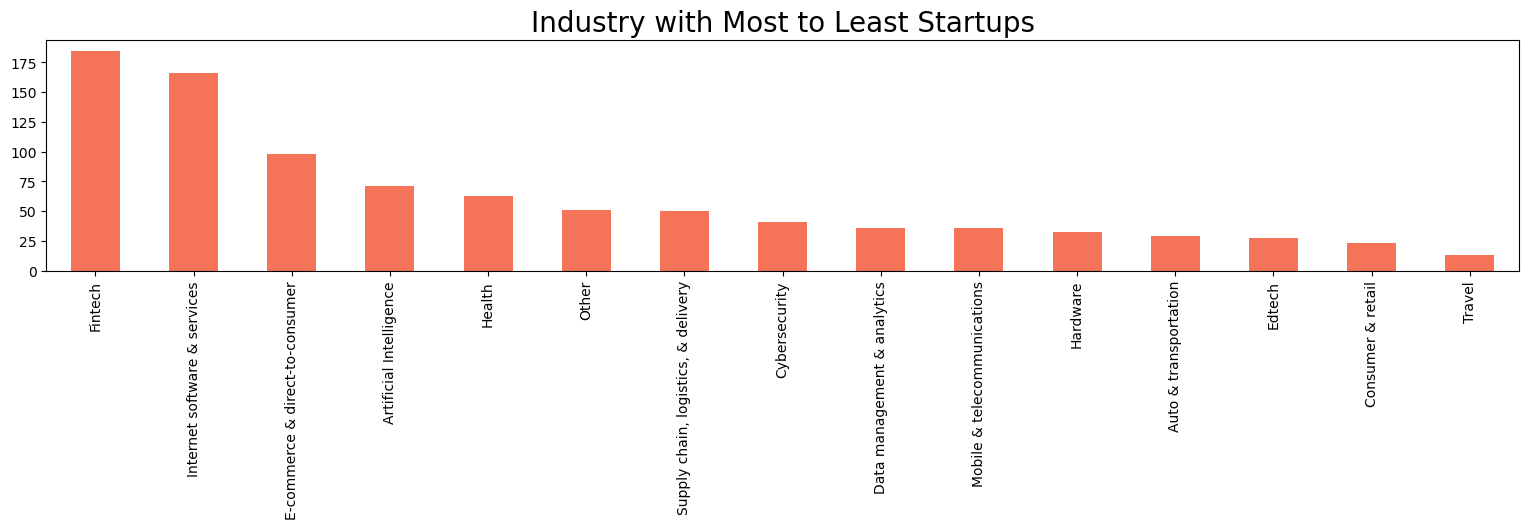

In [11]:
df.Industry.value_counts().plot(kind="bar",figsize=(19,3),color = '#F57358')
plt.title("Industry with Most to Least Startups", fontdict={"fontsize":20})

In [12]:
df.Country.value_counts().head(10)
top_10_country=df.Country.value_counts().head(10)

In [13]:
top_10_country=pd.DataFrame(top_10_country) 

In [14]:
top_10_country.columns

Index(['Country'], dtype='object')

In [15]:
top_10_country=top_10_country.reset_index()
top_10_country.rename(columns={"index":"Country","Country":"No of Startups"},inplace=True)

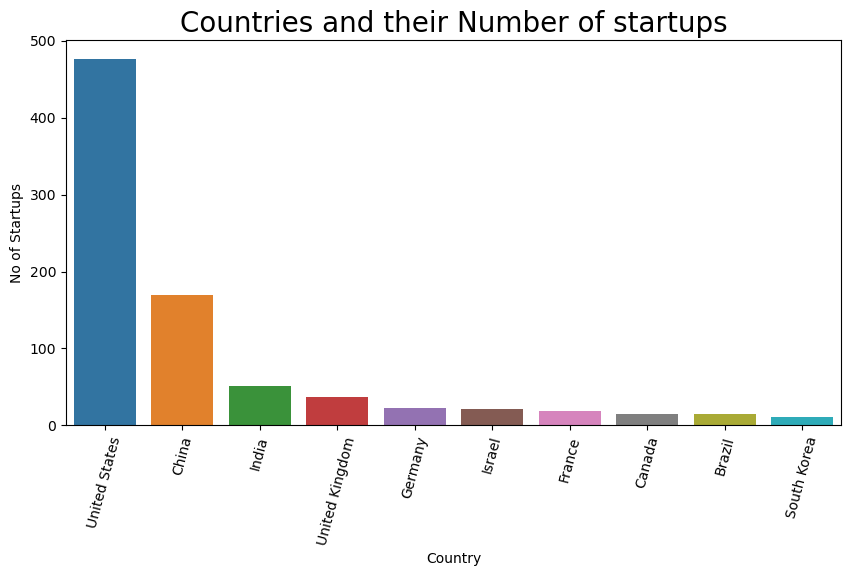

In [16]:
plt.figure(figsize=(10,5))
sns.barplot(x="Country",y="No of Startups", data=top_10_country,)
plt.title("Countries and their Number of startups", fontdict={"fontsize":20})
plt.xticks(rotation=75)
plt.show()

In [17]:
df.Valuation.value_counts().head(10)

1.0    216
2.0     65
1.5     42
1.2     37
3.0     36
1.1     28
1.4     23
4.0     20
1.6     17
1.7     15
Name: Valuation, dtype: int64

In [18]:
#Dividing Datasets based on their valuations

Value50P=df[df.Valuation>50]
Value20P=df[df.Valuation>20]
Value10To20=df[(df.Valuation<20) & (df.Valuation>=10)]
Value5To10=df[(df.Valuation<10) & (df.Valuation>=5)]
Value2To5=df[(df.Valuation<5) & (df.Valuation>=2)]
Value1To2 = df[(df.Valuation<2) & (df.Valuation>=1)]

Valuation_5More=df[df.Valuation>5]

### Data based on Valuation

Number of companies with Valuation above 50 are         3
Number of companies with Valuation between 20 to 50 are 12
Number of companies with Valuation between 10 to 20 are 29
Number of companies with Valuation between 5 to 10 are  82
Number of companies with Valuation between 2 to 5 are   288
Number of companies with Valuation between 1 to 2 are   508

 



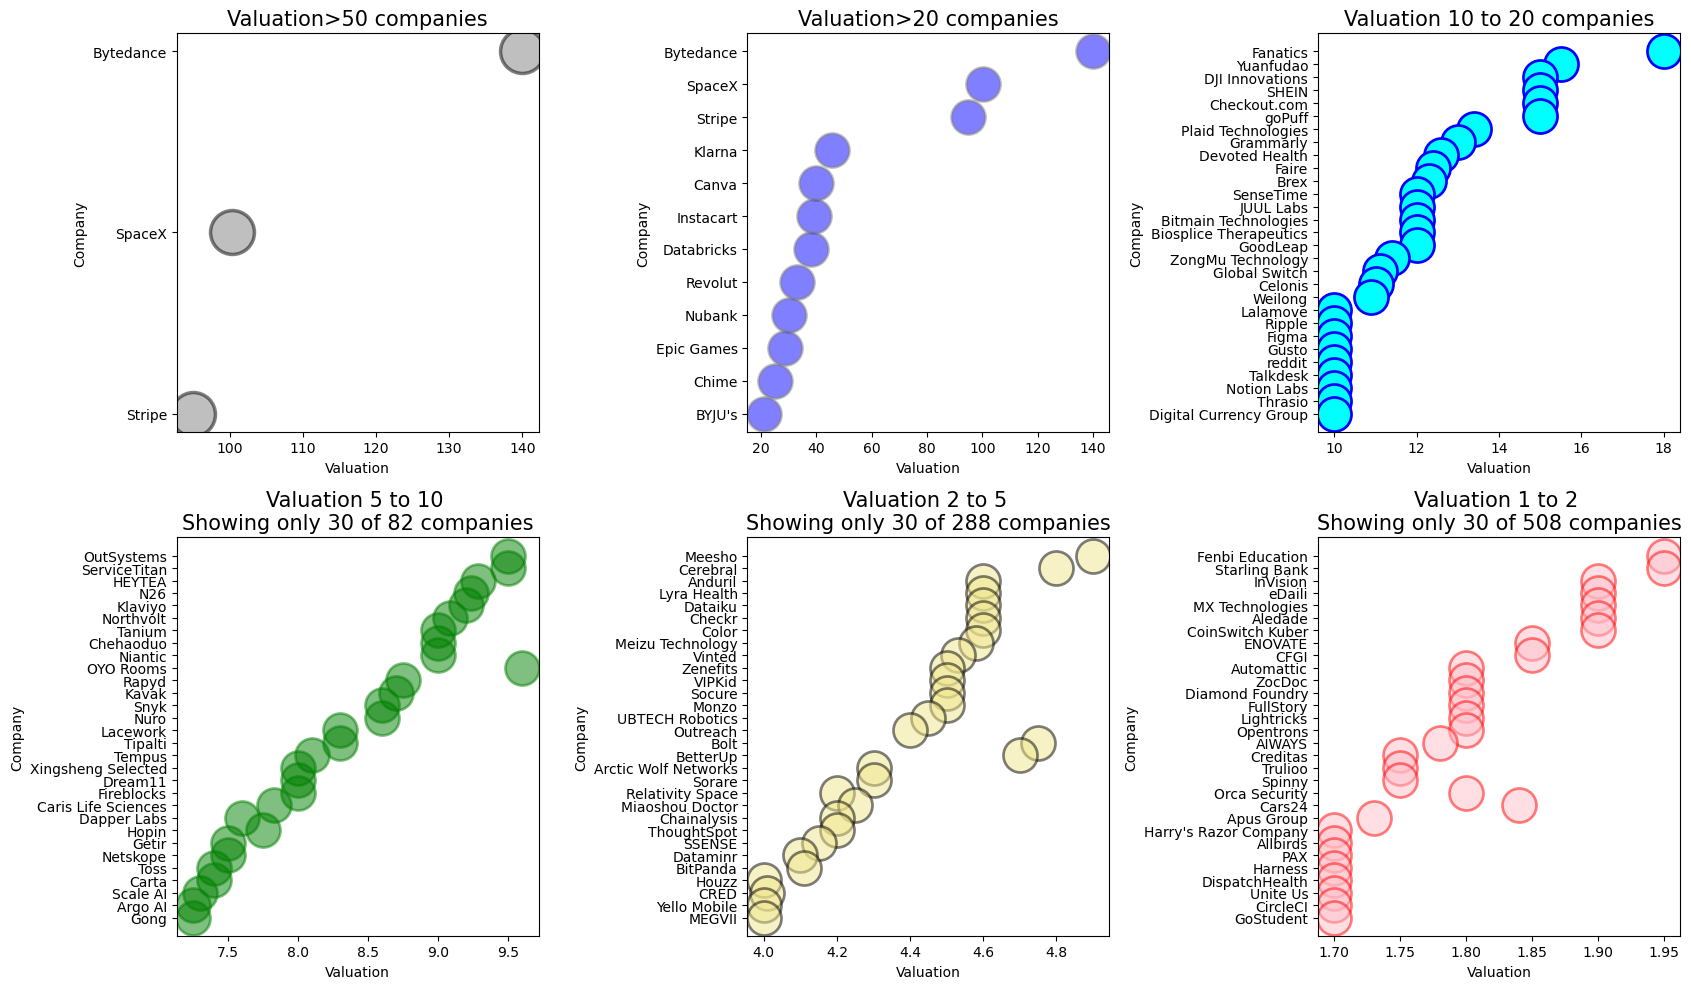

In [19]:
plt.figure(figsize=(17,10))

plt.subplot(2,3,1)
sns.scatterplot(x="Valuation",y="Company",data=Value50P, color="Grey", s=1000, alpha=0.5,edgecolor="black")
plt.title("Valuation>50 companies", fontdict={"fontsize":15})
plt.subplot(2,3,2)
sns.scatterplot(x="Valuation",y="Company",data=Value20P , color="Blue", s=600, alpha=0.5,edgecolor="grey")
plt.title("Valuation>20 companies", fontdict={"fontsize":15})

plt.subplot(2,3,3)
sns.scatterplot(x="Valuation",y="Company",data=Value10To20 , color="cyan", s=600, edgecolor="blue")
plt.title("Valuation 10 to 20 companies", fontdict={"fontsize":15})

plt.subplot(2,3,4)
sns.scatterplot(x="Valuation",y="Company",data=Value5To10.head(30) , color="green", s=600, alpha=0.5, edgecolor="green")
plt.title("Valuation 5 to 10 \nShowing only 30 of 82 companies", fontdict={"fontsize":15})

plt.subplot(2,3,5)
sns.scatterplot(x="Valuation",y="Company",data=Value2To5.head(30) , color="khaki", s=600, alpha=0.5, edgecolor="black")
plt.title("Valuation 2 to 5 \nShowing only 30 of 288 companies", fontdict={"fontsize":15})

plt.subplot(2,3,6)
sns.scatterplot(x="Valuation",y="Company",data=Value1To2.head(30) , color="pink", s=600, alpha=0.5, edgecolor="red")
plt.title("Valuation 1 to 2 \nShowing only 30 of 508 companies", fontdict={"fontsize":15})


plt.tight_layout()


print("Number of companies with Valuation above 50 are         {0}".format(Value50P.Company.nunique()))
print("Number of companies with Valuation between 20 to 50 are {0}".format(Value20P.Company.nunique()))
print("Number of companies with Valuation between 10 to 20 are {0}".format(Value10To20.Company.nunique()))
print("Number of companies with Valuation between 5 to 10 are  {0}".format(Value5To10.Company.nunique()))
print("Number of companies with Valuation between 2 to 5 are   {0}".format(Value2To5.Company.nunique()))
print("Number of companies with Valuation between 1 to 2 are   {0}".format(Value1To2.Company.nunique()))
print("\n \n")

We can see the trends in different areas of valuation of different segments and how it is clustered at valuations below 20 especially at 1-2 valuations while very few starups have valuation above 50 (only 3)

### Further below graph shows all the companies and their valuation countrywise

In [20]:
px.scatter(x="Valuation",y="Company",data_frame=st, color="Country",title="Companies and their valuation countrywise")

In [21]:
px.scatter_matrix(dimensions=['Valuation', 'year', 'Country',"Industry"],size="Valuation",data_frame=Value20P,color="Company", title="Details of startups between 20 to 50 Valuation vs Country/Year/Industry")

Details of startups between 20 to 50 Valuation showing relashionship of each variable with variable-> Country or Year or Industry ( as these are more populated than startups above 50 and also have good scope and impact)

### Top 3 countries( with most number of startups) analysis

In [22]:
aTemp=top_10_country["Country"].head(3)
aTemp=list(aTemp)
aTemp

['United States', 'China', 'India']

In [23]:
Country_top3=st[st["Country"].isin(aTemp)]

In [24]:
Country_top3.columns

Index(['Company', 'Valuation', 'Date', 'Country', 'City', 'Industry',
       'Investors', 'year', 'month', 'day'],
      dtype='object')

In [25]:
px.scatter(y="Valuation",x="year",data_frame=Country_top3, color="Country",size="Valuation",hover_data=['Company', 'Valuation', 'Date', 'Country', 'City', 'Industry'])

ndia- On clicking "India" we can see increased number of startups after the year 2018 while Byju's being the biggest valuation- since 2017 - The maximum no of startups are in 2021 in India - showing a rising trend of new startups and improved environment for new business- India has Byju's above 20 valuation and 6 startups between 5-10 value with Ola cabs being oldest since 2014 rest comparitevely young (since 2018)
USA has biggest startups in 2012-SpaceX and 2014-Stripe and has increased number of startups since 2017 - with 2 above 90 valuation and 4 between 20-40 valuation and an improved trend since 2018 in increase in number of new busniess
China has increase in number of startups since 2015 with ByteDance being highest valued since 2017 and various other startups after 2014 sprouting most upto 20 Valuation

In [26]:
px.bar(y="Valuation",x="Industry",data_frame=Country_top3, color="Country",hover_data=['Company', 'Valuation', 'Date', 'Country', 'City', 'Industry'])

Fintech, Internet software & services, AI are top 3 industries with unicorns
USA has significant proportion in Fintech, Internet software & services followed by India(includes RazorPay/CRED/PolicyBazaar in Fintech) and China
AI industry is dominated by China (includes ByteDance) and then USA
Edtech has a good proportion of India market

In [27]:
Country_top3.head(1)

,Company,Valuation,Date,Country,City,Industry,Investors,year,month,day
0,Bytedance,140.0,4/7/2017,China,Beijing,Artificial intelligence,"0 Sequoia Capital China, SIG Asia Investm...",2017,7,4


In [28]:
px.bar(y="Valuation",x="Industry",data_frame=Country_top3[Country_top3.Country=="India"], color="City",hover_data=['Company', 'Valuation', 'Date', 'Country', 'City', 'Industry'])

# Thank You...